# Label-flipping data poisoning: контрольный и атакованный сценарии

Ноутбук является воспроизводимой демонстрацией возможностей стенда: он строит Non-IID-разбиение MNIST, показывает реализованный план отравления, обучает модель в **чистом** и **атакованном** сценариях, а затем сопоставляет результаты.

> Один парный запуск — наглядная проверка конвейера, но не достаточное основание для научного вывода. Для отчёта следует повторить эксперимент минимум на трёх seed.

## 1. Параметры сценария и подготовка окружения

Обе части эксперимента используют одинаковые датасет, модель, разбиение и seed. Единственное различие — включённость label-flip атаки. Это необходимо, чтобы разница метрик могла быть связана именно с атакой.

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import Markdown, display
except ImportError:  # Позволяет проверить ячейки и вне Jupyter.
    Markdown = str
    def display(value):
        return value

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    candidates = [PROJECT_ROOT, *PROJECT_ROOT.parents]
    PROJECT_ROOT = next(path for path in candidates if (path / 'pyproject.toml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from fl_benchmark.attacks.label_flip import build_label_flip_plan
from fl_benchmark.config import load_config
from fl_benchmark.datasets.loader import load_datasets
from fl_benchmark.datasets.partitioning import create_partitions, get_targets
from fl_benchmark.datasets.statistics import compute_partition_statistics
from fl_benchmark.task import run_local_simulation

BASE_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'mnist_label_flip.toml'
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / 'notebooks' / 'results'
NOTEBOOK_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_PICS_DIR = PROJECT_ROOT / 'practice_report' / 'pics'
REPORT_PICS_DIR.mkdir(parents=True, exist_ok=True)

base_config = load_config(BASE_CONFIG_PATH)
common_tracking = replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR)

clean_config = replace(
    base_config,
    name='mnist-clean-control',
    attack=replace(base_config.attack, enabled=False, type='none', malicious_fraction=0.0, poison_fraction=0.0),
    tracking=replace(common_tracking, experiment_name='mnist-clean-control'),
    source_path=None,
)
attack_config = replace(
    base_config,
    name='mnist-label-flip-attack',
    tracking=replace(common_tracking, experiment_name='mnist-label-flip-attack'),
    source_path=None,
)

scenario_table = pd.DataFrame([
    ('Датасет', base_config.dataset.name),
    ('Модель', base_config.model.name),
    ('Стратегия агрегации', base_config.strategy.name),
    ('Клиенты / раунды', f'{base_config.partition.num_clients} / {base_config.federation.num_rounds}'),
    ('Non-IID режим', f'{base_config.partition.type}, alpha={base_config.partition.alpha}'),
    ('Локальные эпохи / learning rate', f'{base_config.training.local_epochs} / {base_config.training.learning_rate}'),
    ('Атака', f'label flip: {attack_config.attack.source_label} → {attack_config.attack.target_label}'),
    ('Вредоносные клиенты / доля отравления', f'{attack_config.attack.malicious_fraction:.0%} / {attack_config.attack.poison_fraction:.0%}'),
    ('Seed (разбиение / обучение / атака)', f'{base_config.partition.seed} / {base_config.training.seed} / {attack_config.attack.seed}'),
], columns=['Параметр', 'Значение'])
display(scenario_table)
print(f'Корень проекта: {PROJECT_ROOT}')
print(f'Каталог результатов ноутбука: {NOTEBOOK_RESULTS_DIR}')

,Параметр,Значение
0,Датасет,mnist
1,Модель,mnist-cnn
2,Стратегия агрегации,fedavg
3,Клиенты / раунды,10 / 5
4,Non-IID режим,"dirichlet, alpha=0.5"
5,Локальные эпохи / learning rate,1 / 0.01
6,Атака,label flip: 1 → 7
7,Вредоносные клиенты / доля отравления,20% / 50%
8,Seed (разбиение / обучение / атака),42 / 42 / 42


Корень проекта: C:\Users\neko\Desktop\projects\fed-learning-stand
Каталог результатов ноутбука: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results


## 2. Non-IID-разбиение и исходная статистика

Здесь показаны размер выборки каждого клиента, абсолютное и нормированное распределения классов, а также entropy и Jensen–Shannon divergence. Красным отмечены клиенты, которые будут участвовать в атаке.

,client_id,роль,num_examples,num_classes,entropy,js_divergence,max_class_fraction,imbalance_ratio
0,0,вредоносный,5669,10,2.763039,0.149579,0.266361,38.717949
1,1,честный,6558,10,1.947109,0.340865,0.421470,145.473684
2,2,честный,5193,10,2.805736,0.126478,0.279800,16.895349
3,3,честный,9858,10,2.701288,0.161481,0.263542,324.750000
4,4,честный,4116,10,2.853040,0.141588,0.215500,19.711111
5,5,честный,4606,10,2.929246,0.102907,0.256839,17.144928
6,6,честный,10756,10,2.579138,0.205664,0.290814,1042.666667
7,7,вредоносный,3576,10,2.136336,0.290717,0.456935,1634.000000
8,8,честный,5684,10,2.637645,0.195135,0.319669,90.850000
9,9,честный,3984,10,2.290201,0.263737,0.437500,871.500000


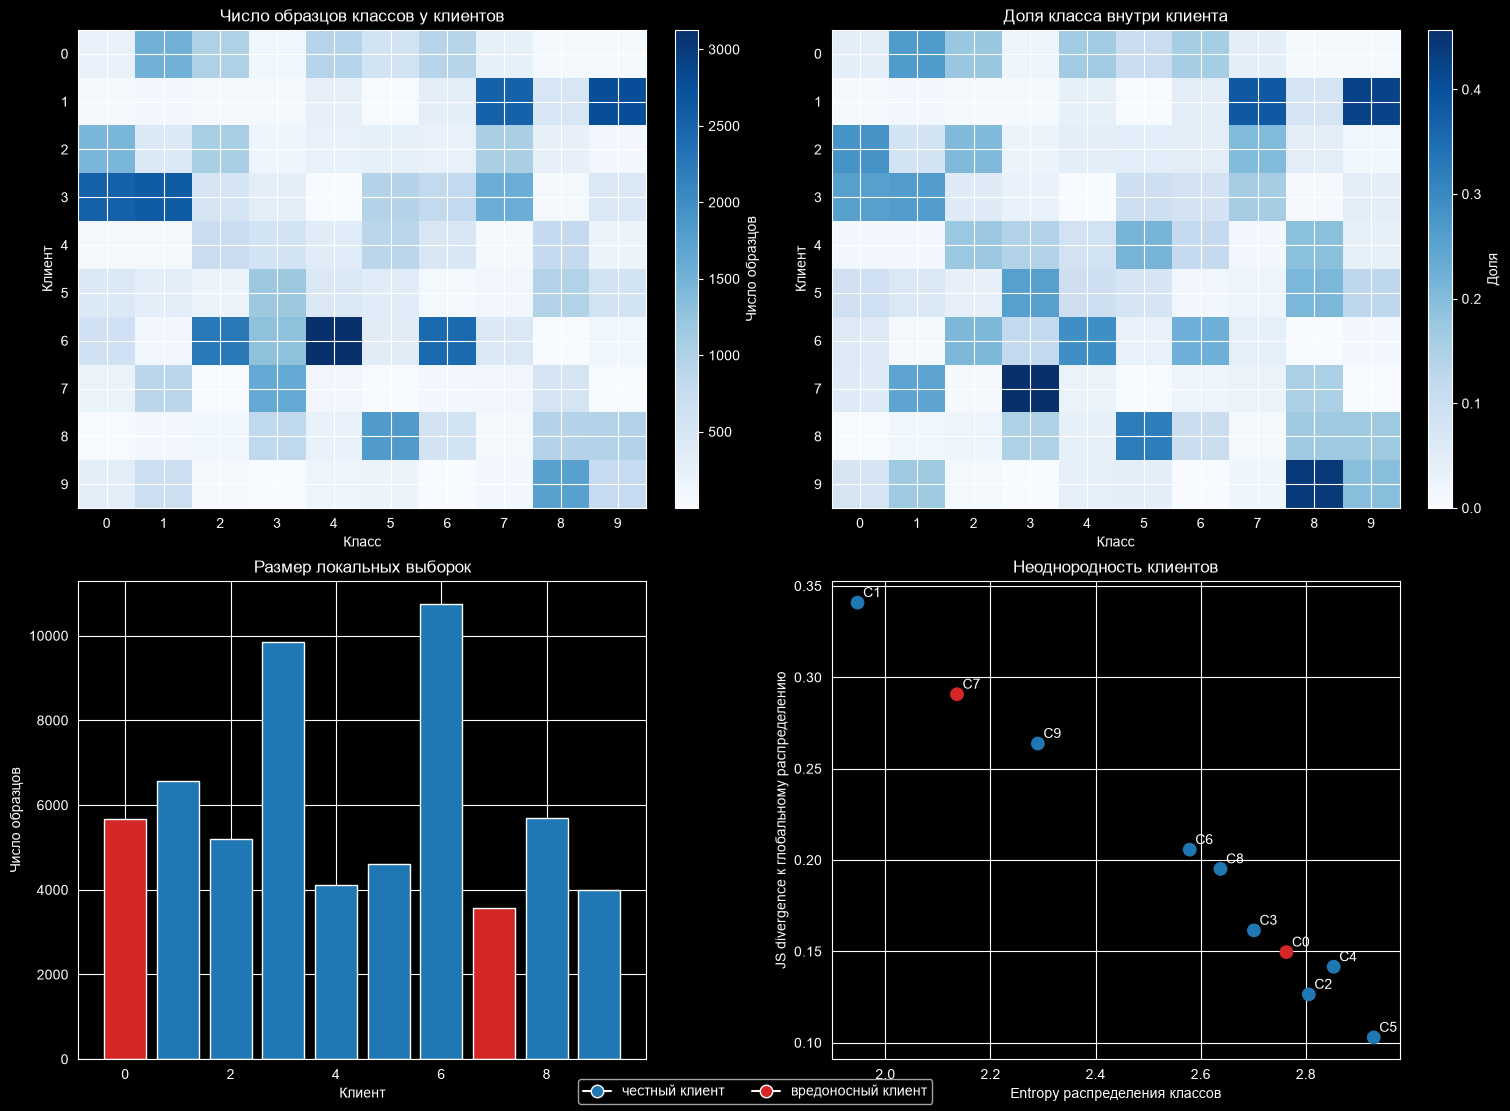

In [2]:
bundle = load_datasets(attack_config.dataset)
targets = get_targets(bundle.train)
partitions = create_partitions(bundle.train, attack_config.partition)
partition_statistics = compute_partition_statistics(targets, partitions, attack_config.model.num_classes)
attack_plan = build_label_flip_plan(targets, partitions, attack_config.attack)

stats = partition_statistics.statistics.copy().sort_values('client_id')
matrix = partition_statistics.matrix.copy().set_index('client_id')
malicious_clients = set(attack_plan.malicious_clients)
stats['роль'] = np.where(stats['client_id'].isin(malicious_clients), 'вредоносный', 'честный')
display(stats[['client_id', 'роль', 'num_examples', 'num_classes', 'entropy', 'js_divergence', 'max_class_fraction', 'imbalance_ratio']])

normalized_matrix = matrix.div(matrix.sum(axis=1), axis=0)
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

im0 = axes[0, 0].imshow(matrix.to_numpy(), aspect='auto', cmap='Blues')
axes[0, 0].set(title='Число образцов классов у клиентов', xlabel='Класс', ylabel='Клиент')
axes[0, 0].set_xticks(range(attack_config.model.num_classes))
axes[0, 0].set_yticks(range(len(matrix)))
fig.colorbar(im0, ax=axes[0, 0], label='Число образцов')

im1 = axes[0, 1].imshow(normalized_matrix.to_numpy(), aspect='auto', cmap='Blues', vmin=0, vmax=normalized_matrix.to_numpy().max())
axes[0, 1].set(title='Доля класса внутри клиента', xlabel='Класс', ylabel='Клиент')
axes[0, 1].set_xticks(range(attack_config.model.num_classes))
axes[0, 1].set_yticks(range(len(matrix)))
fig.colorbar(im1, ax=axes[0, 1], label='Доля')

colors = ['tab:red' if cid in malicious_clients else 'tab:blue' for cid in stats['client_id']]
axes[1, 0].bar(stats['client_id'], stats['num_examples'], color=colors)
axes[1, 0].set(title='Размер локальных выборок', xlabel='Клиент', ylabel='Число образцов')

axes[1, 1].scatter(stats['entropy'], stats['js_divergence'], c=colors, s=80)
for row in stats.itertuples():
    axes[1, 1].annotate(f'C{row.client_id}', (row.entropy, row.js_divergence), xytext=(4, 4), textcoords='offset points')
axes[1, 1].set(title='Неоднородность клиентов', xlabel='Entropy распределения классов', ylabel='JS divergence к глобальному распределению')
fig.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:blue', label='честный клиент', markersize=9), plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red', label='вредоносный клиент', markersize=9)], loc='lower center', ncol=2)
fig.savefig(REPORT_PICS_DIR / '02_single_label_flip_comparison_partition_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. План label-flip атаки

Атака не изменяет исходный датасет на диске. Для выбранных клиентов стенд создаёт обёртку локального набора данных, в которой часть объектов исходного класса передаётся модели с целевой меткой.

,клиент,исходные метки,изменено меток,доля среди исходного класса
0,0,1510,755,50.0%
1,7,883,442,50.1%


{
  "enabled": true,
  "type": "label_flip",
  "seed": 42,
  "malicious_fraction": 0.2,
  "poison_fraction": 0.5,
  "source_label": 1,
  "target_label": 7,
  "label_flips": [
    {
      "source_label": 1,
      "target_label": 7
    }
  ],
  "malicious_clients": [
    0,
    7
  ],
  "num_malicious_clients": 2,
  "poisoned_examples_per_client": {
    "0": 755,
    "7": 442
  },
  "total_poisoned_examples": 1197,
  "poisoned_examples_by_flip": {
    "1->7": 1197
  }
}


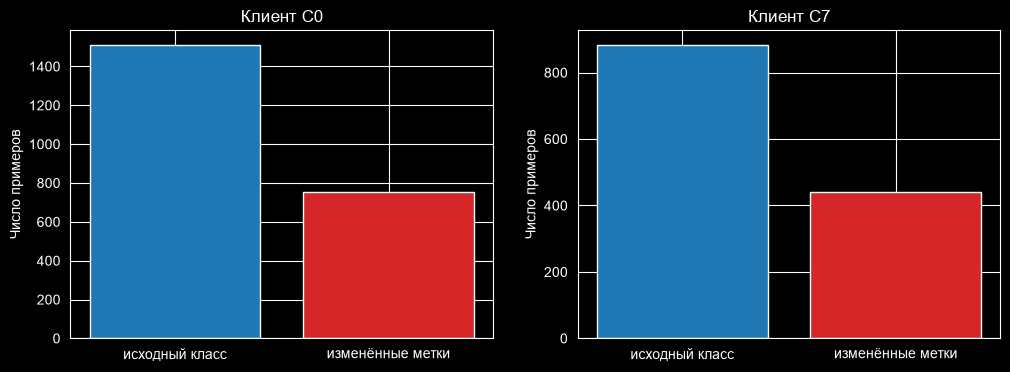

In [3]:
manifest = attack_plan.manifest()
attack_rows = []
for client_id in attack_plan.malicious_clients:
    local_indices = np.asarray(partitions[client_id], dtype=int)
    source_count = int((targets[local_indices] == attack_config.attack.source_label).sum())
    poisoned_count = len(attack_plan.poisoned_indices.get(client_id, ()))
    attack_rows.append({'клиент': client_id, 'исходные метки': source_count, 'изменено меток': poisoned_count, 'доля среди исходного класса': poisoned_count / source_count if source_count else 0.0})
attack_table = pd.DataFrame(attack_rows)
display(attack_table.style.format({'доля среди исходного класса': '{:.1%}'}))
print(json.dumps({key: value for key, value in manifest.items() if key != 'poisoned_indices'}, ensure_ascii=False, indent=2))

if attack_table.empty or attack_plan.total_poisoned_examples == 0:
    raise RuntimeError('В текущем плане нет отравлённых примеров. Измените параметры атаки или seed.')

fig, axes = plt.subplots(1, len(attack_table), figsize=(6 * len(attack_table), 4), squeeze=False)
for axis, row in zip(axes[0], attack_table.itertuples(index=False, name=None), strict=True):
    axis.bar(['исходный класс', 'изменённые метки'], [row[1], row[2]], color=['tab:blue', 'tab:red'])
    axis.set(title=f'Клиент C{row[0]}', ylabel='Число примеров')
fig.savefig(REPORT_PICS_DIR / '02_single_label_flip_comparison_attack_scenario.png', dpi=200, bbox_inches='tight')
plt.show()

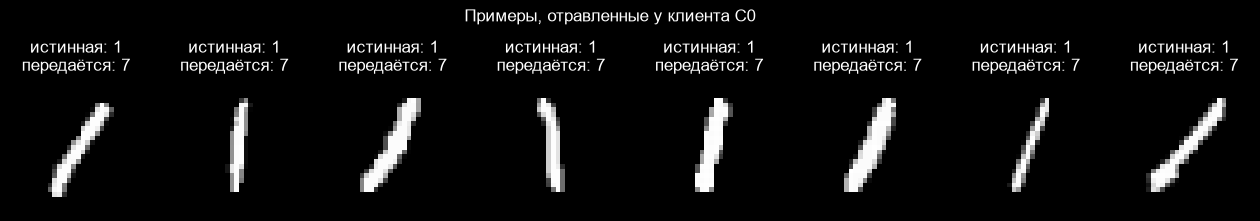

In [4]:
client_id = attack_plan.malicious_clients[0]
poisoned_indices = attack_plan.poisoned_indices[client_id]
shown_indices = poisoned_indices[:min(8, len(poisoned_indices))]
fig, axes = plt.subplots(1, len(shown_indices), figsize=(2 * len(shown_indices), 2.8), squeeze=False)
for axis, sample_index in zip(axes[0], shown_indices, strict=True):
    image, true_label = bundle.train[sample_index]
    axis.imshow(image.squeeze(), cmap='gray')
    axis.set_title(f'истинная: {true_label}\nпередаётся: {attack_config.attack.target_label}')
    axis.axis('off')
fig.suptitle(f'Примеры, отравленные у клиента C{client_id}')
fig.savefig(REPORT_PICS_DIR / '02_single_label_flip_comparison_poisoned_examples.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Полный парный запуск

Ячейка запускает два полных эксперимента: контрольный без атаки и атакованный. На CPU выполнение может занимать несколько минут. Каждый запуск сохраняется в отдельном каталоге `notebooks/results/`. Повторный запуск создаёт новые каталоги, а не перезаписывает предыдущие результаты.

In [5]:
RUN_FULL_EXPERIMENTS = True  # Установите False, чтобы изучать ранее сохранённые результаты.

if RUN_FULL_EXPERIMENTS:
    print('Запуск 1/2: чистый контрольный сценарий...')
    clean_output_dir = run_local_simulation(clean_config)
    print(f'Готово: {clean_output_dir}')
    print('Запуск 2/2: сценарий с label-flip атакой...')
    attack_output_dir = run_local_simulation(attack_config)
    print(f'Готово: {attack_output_dir}')
else:
    def latest_result(prefix):
        candidates = sorted(NOTEBOOK_RESULTS_DIR.glob(f'{prefix}-*'), key=lambda path: path.stat().st_mtime)
        if not candidates:
            raise FileNotFoundError(f'Не найдены результаты {prefix!r} в {NOTEBOOK_RESULTS_DIR}')
        return candidates[-1]
    clean_output_dir = latest_result('mnist-clean-control')
    attack_output_dir = latest_result('mnist-label-flip-attack')
    print(f'Используются ранее сохранённые результаты:\n  clean:  {clean_output_dir}\n  attack: {attack_output_dir}')

Запуск 1/2: чистый контрольный сценарий...
Готово: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-clean-control-20261125-095749-e51deec4
Запуск 2/2: сценарий с label-flip атакой...
Готово: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-label-flip-attack-20261125-100023-aa3d7842


## 5. Сопоставление обучения и итоговых метрик

Сравнение использует только фактически сохранённые результаты. Изменения метрик интерпретируются как наблюдение одного запуска; устойчивость эффекта необходимо проверять повторениями с другими seed.

,Метрика,Контроль,Label flip,Изменение (атака − контроль)
0,Итоговая accuracy,0.97310,0.97390,+0.00080
1,Итоговый loss,0.08500,0.08612,+0.00112
2,Итоговый macro F1,0.97285,0.97371,+0.00086
3,"Время выполнения, с",149.79249,153.15647,+3.36397
4,"Передано данных, байт",42346400.00000,42346400.00000,+0.00000


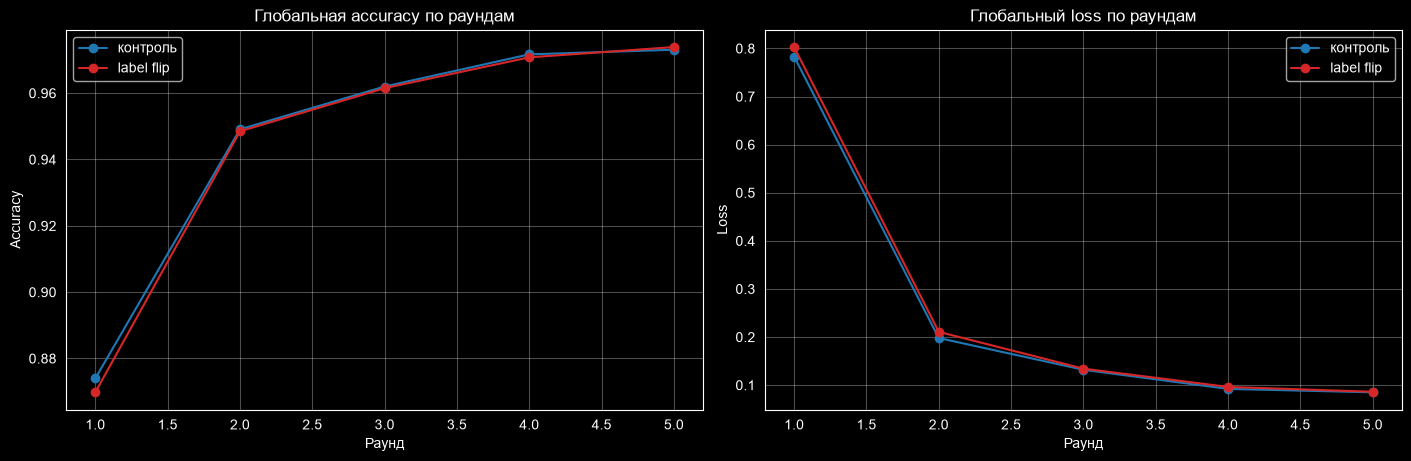

In [6]:
def load_run(output_dir):
    confusion = pd.read_csv(output_dir / 'final_confusion_matrix.csv').to_numpy()
    per_class_path = output_dir / 'final_per_class_metrics.csv'
    if per_class_path.exists():
        per_class = pd.read_csv(per_class_path)
    else:
        support = confusion.sum(axis=1)
        per_class = pd.DataFrame({'class_id': np.arange(len(support)), 'support': support, 'accuracy': np.divide(np.diag(confusion), support, out=np.zeros_like(support, dtype=float), where=support != 0), 'loss': np.nan})
    return {'path': output_dir, 'summary': json.loads((output_dir / 'summary.json').read_text(encoding='utf-8')), 'rounds': pd.read_csv(output_dir / 'round_metrics.csv'), 'clients': pd.read_csv(output_dir / 'client_metrics.csv'), 'confusion': confusion, 'per_class': per_class, 'manifest': json.loads((output_dir / 'attack_manifest.json').read_text(encoding='utf-8'))}

clean_run = load_run(clean_output_dir)
attack_run = load_run(attack_output_dir)
comparison = pd.DataFrame([
    ('Итоговая accuracy', clean_run['summary']['final_accuracy'], attack_run['summary']['final_accuracy']),
    ('Итоговый loss', clean_run['summary']['final_loss'], attack_run['summary']['final_loss']),
    ('Итоговый macro F1', clean_run['summary']['final_macro_f1'], attack_run['summary']['final_macro_f1']),
    ('Время выполнения, с', clean_run['summary']['total_duration_seconds'], attack_run['summary']['total_duration_seconds']),
    ('Передано данных, байт', clean_run['summary']['total_communication_bytes'], attack_run['summary']['total_communication_bytes']),
], columns=['Метрика', 'Контроль', 'Label flip'])
comparison['Изменение (атака − контроль)'] = comparison['Label flip'] - comparison['Контроль']
display(comparison.style.format({'Контроль': '{:.5f}', 'Label flip': '{:.5f}', 'Изменение (атака − контроль)': '{:+.5f}'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for run, label, color in [(clean_run, 'контроль', 'tab:blue'), (attack_run, 'label flip', 'tab:red')]:
    axes[0].plot(run['rounds']['round'], run['rounds']['global_accuracy'], marker='o', label=label, color=color)
    axes[1].plot(run['rounds']['round'], run['rounds']['global_loss'], marker='o', label=label, color=color)
axes[0].set(title='Глобальная accuracy по раундам', xlabel='Раунд', ylabel='Accuracy')
axes[1].set(title='Глобальный loss по раундам', xlabel='Раунд', ylabel='Loss')
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
fig.savefig(REPORT_PICS_DIR / '02_single_label_flip_comparison_global_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

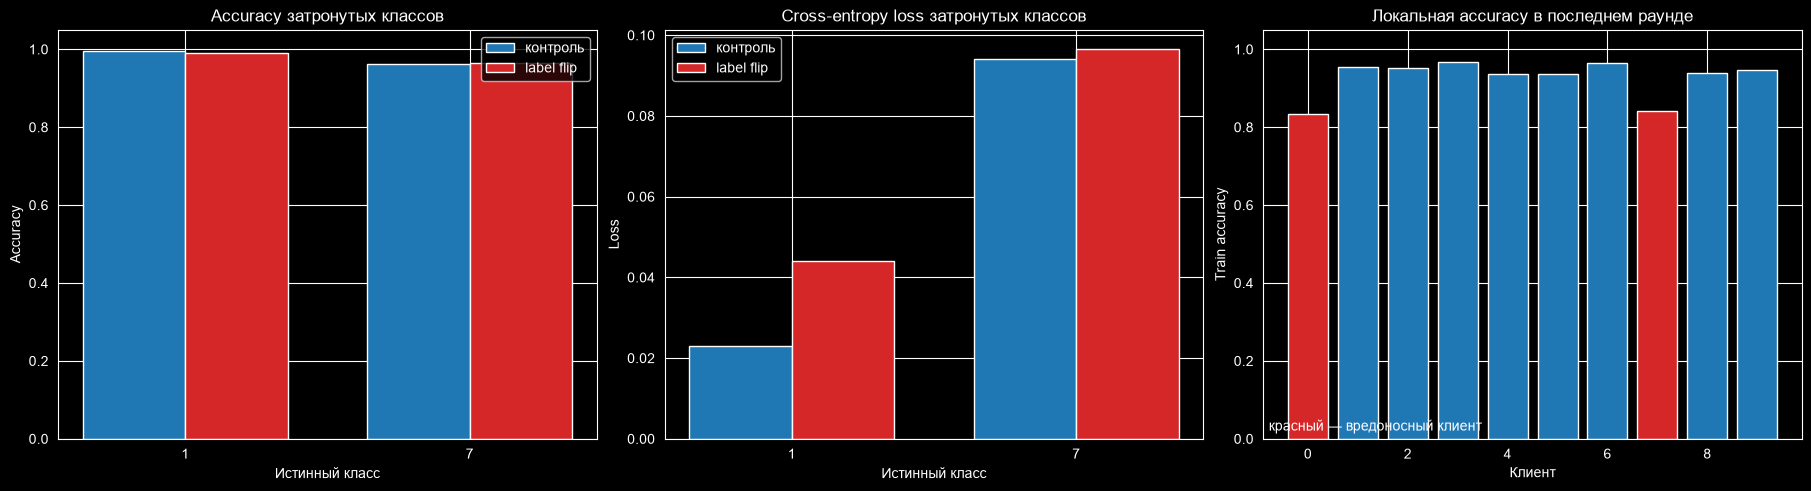

,класс,контрольная accuracy,accuracy при атаке,контрольный loss,loss при атаке,изменение accuracy,изменение loss
0,1,99.559%,98.943%,0.02290,0.04394,-0.617%,+0.02104
1,7,96.304%,96.498%,0.09416,0.09651,+0.195%,+0.00235


In [7]:
focus_classes = [attack_config.attack.source_label, attack_config.attack.target_label]
clean_focus = clean_run['per_class'].set_index('class_id').reindex(focus_classes)
attack_focus = attack_run['per_class'].set_index('class_id').reindex(focus_classes)
final_client_metrics = attack_run['clients'].sort_values('round').groupby('partition_id', as_index=False).tail(1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
width = 0.36
x = np.arange(len(focus_classes))
axes[0].bar(x - width / 2, clean_focus['accuracy'], width, label='контроль', color='tab:blue')
axes[0].bar(x + width / 2, attack_focus['accuracy'], width, label='label flip', color='tab:red')
axes[0].set(title='Accuracy затронутых классов', xlabel='Истинный класс', ylabel='Accuracy', xticks=x, xticklabels=focus_classes, ylim=(0, 1.05))
axes[0].legend()
if clean_focus['loss'].isna().any() or attack_focus['loss'].isna().any():
    axes[1].text(0.5, 0.5, 'Class-wise loss отсутствует в старых результатах.\nЗапустите сценарий заново.', ha='center', va='center', transform=axes[1].transAxes)
    axes[1].set_axis_off()
else:
    axes[1].bar(x - width / 2, clean_focus['loss'], width, label='контроль', color='tab:blue')
    axes[1].bar(x + width / 2, attack_focus['loss'], width, label='label flip', color='tab:red')
    axes[1].set(title='Cross-entropy loss затронутых классов', xlabel='Истинный класс', ylabel='Loss', xticks=x, xticklabels=focus_classes)
    axes[1].legend()
client_colors = np.where(final_client_metrics['is_malicious'], 'tab:red', 'tab:blue')
axes[2].bar(final_client_metrics['partition_id'], final_client_metrics['train_accuracy'], color=client_colors)
axes[2].set(title='Локальная accuracy в последнем раунде', xlabel='Клиент', ylabel='Train accuracy', ylim=(0, 1.05))
axes[2].text(0.01, 0.02, 'красный — вредоносный клиент', transform=axes[2].transAxes)
fig.savefig(REPORT_PICS_DIR / '02_single_label_flip_comparison_per_class_effect.png', dpi=200, bbox_inches='tight')
plt.show()

focus = pd.DataFrame({'класс': focus_classes, 'контрольная accuracy': clean_focus['accuracy'].to_numpy(), 'accuracy при атаке': attack_focus['accuracy'].to_numpy(), 'контрольный loss': clean_focus['loss'].to_numpy(), 'loss при атаке': attack_focus['loss'].to_numpy()})
focus['изменение accuracy'] = focus['accuracy при атаке'] - focus['контрольная accuracy']
focus['изменение loss'] = focus['loss при атаке'] - focus['контрольный loss']
display(focus.style.format({'контрольная accuracy': '{:.3%}', 'accuracy при атаке': '{:.3%}', 'контрольный loss': '{:.5f}', 'loss при атаке': '{:.5f}', 'изменение accuracy': '{:+.3%}', 'изменение loss': '{:+.5f}'}))

## 6. Сводка, артефакты и границы вывода

Ниже формируется краткая проверяемая сводка. Она фиксирует, что атака действительно была применена, и отделяет это утверждение от статистического вывода об её влиянии.

In [8]:
delta_accuracy = attack_run['summary']['final_accuracy'] - clean_run['summary']['final_accuracy']
delta_loss = attack_run['summary']['final_loss'] - clean_run['summary']['final_loss']
display(Markdown(f'''
### Итог одного парного запуска

- Контрольный результат: accuracy **{clean_run['summary']['final_accuracy']:.4f}**, loss **{clean_run['summary']['final_loss']:.4f}**.
- При label flip: accuracy **{attack_run['summary']['final_accuracy']:.4f}**, loss **{attack_run['summary']['final_loss']:.4f}**.
- Разность «атака − контроль»: accuracy **{delta_accuracy:+.4f}**, loss **{delta_loss:+.4f}**.
- Реализованный план атаки: **{attack_run['manifest']['num_malicious_clients']}** вредоносных клиента(ов), **{attack_run['manifest']['total_poisoned_examples']}** изменённых меток {attack_config.attack.source_label} → {attack_config.attack.target_label}.

Это наблюдение одного seed. Для содержательного вывода об эффекте атаки нужно повторить тот же парный сценарий минимум для трёх seed и анализировать среднее значение и разброс.
'''))
artifacts = pd.DataFrame([
    ('Контрольный запуск', str(clean_run['path'])),
    ('Атакованный запуск', str(attack_run['path'])),
    ('Метрики по раундам', 'round_metrics.csv'),
    ('Метрики клиентов', 'client_metrics.csv'),
    ('План атаки', 'attack_manifest.json'),
    ('Статистика разбиения', 'partition_statistics.csv / partition_matrix.csv'),
    ('Матрица ошибок', 'final_confusion_matrix.csv'),
], columns=['Артефакт', 'Расположение'])
display(artifacts)


### Итог одного парного запуска

- Контрольный результат: accuracy **0.9731**, loss **0.0850**.
- При label flip: accuracy **0.9739**, loss **0.0861**.
- Разность «атака − контроль»: accuracy **+0.0008**, loss **+0.0011**.
- Реализованный план атаки: **2** вредоносных клиента(ов), **1197** изменённых меток 1 → 7.

Это наблюдение одного seed. Для содержательного вывода об эффекте атаки нужно повторить тот же парный сценарий минимум для трёх seed и анализировать среднее значение и разброс.


,Артефакт,Расположение
0,Контрольный запуск,C:\Users\neko\Desktop\projects\fed-learning-st...
1,Атакованный запуск,C:\Users\neko\Desktop\projects\fed-learning-st...
2,Метрики по раундам,round_metrics.csv
3,Метрики клиентов,client_metrics.csv
4,План атаки,attack_manifest.json
5,Статистика разбиения,partition_statistics.csv / partition_matrix.csv
6,Матрица ошибок,final_confusion_matrix.csv
